In [ ]:
%pip install antspyx
%pip install tqdm
%pip install ipywidgets
%pip install torch
%pip install scikit-image
%pip install --upgrade SimpleITK
%pip install nibabel

In [1]:
import os
import ants
import numpy as np
from pathlib import Path
from tqdm import tqdm
from ipywidgets import interact, IntSlider, Dropdown
import matplotlib.pyplot as plt
import torch
from skimage import draw, measure, color, filters, segmentation, morphology
from scipy import ndimage
import numpy as np
from scipy.ndimage import center_of_mass
from skimage.measure import regionprops
from preprocess import Preprocess
import warnings
from scipy.ndimage import binary_fill_holes
from scipy.spatial import ConvexHull
import numpy as np
from scipy.ndimage import label, distance_transform_edt, binary_dilation
from skimage.measure import regionprops
from skimage import morphology
warnings.filterwarnings('ignore')
from scipy.ndimage import label, center_of_mass 
from skimage import morphology
from skimage.measure import regionprops
import numpy as np

In [2]:
def load_slice(image_path, slice_idx=None, axis=2):
    """
    Load MRI and extract a 2D slice
    
    Args:
        image_path: path to NIfTI
        slice_idx: which slice (None = middle)
        axis: 0=sagittal, 1=coronal, 2=axial
    
    Returns:
        img: ANTs image
        slice_2d: 2D numpy array
        slice_idx: actual slice index used
    """
    img = ants.image_read(str(image_path))
    data_3d = img.numpy()
    
    # Get middle slice if not specified
    if slice_idx is None:
        slice_idx = data_3d.shape[axis] // 2
    
    # Extract slice
    if axis == 0:
        slice_2d = data_3d[slice_idx, :, :]
    elif axis == 1:
        slice_2d = data_3d[:, slice_idx, :]
    else:  # axis == 2
        slice_2d = data_3d[:, :, slice_idx]
    
    print(f"Loaded slice {slice_idx} (axis={axis})")
    print(f"  Shape: {slice_2d.shape}")
    print(f"  Range: [{slice_2d.min():.2f}, {slice_2d.max():.2f}]")
    
    return img, slice_2d, slice_idx

# def remove_noise(img_slice):
#     thresh = filters.threshold_li(img_slice)
#     rough_mask = img_slice > thresh

#     cleaned = morphology.binary_closing(rough_mask, morphology.disk(3))
#     labels = measure.label(cleaned)
#     if labels.max() > 0:
#         brain_blob = (labels == (np.argmax(np.bincount(labels.flat)[1:]) + 1))
#     else:
#         brain_blob = cleaned

#     final_brain_mask = ndimage.binary_fill_holes(brain_blob)
#     # Close sulci (natural brain surface folds) so they don't appear as artifact dents.
#     # Sulci are typically 5-15px wide; disk(8) bridges them without merging brain with skull.
#     final_brain_mask = morphology.binary_closing(final_brain_mask, morphology.disk(8))
#     return final_brain_mask

def fill_brain(img_slice, clean_brain_mask, head_mask=None):
    tight_hull = morphology.convex_hull_image(clean_brain_mask)
    closed_brain = tight_hull & head_mask if head_mask is not None else tight_hull
    closed_brain = morphology.binary_closing(closed_brain, morphology.disk(5))
    thin_boundary = closed_brain ^ morphology.binary_erosion(closed_brain, morphology.disk(1))

    brain_only = np.where(closed_brain, img_slice, 0)
    
    return brain_only

def convert_to_mask(img_slice, contour):
    mask = np.zeros(img_slice.shape, dtype=np.uint8)

    r = contour[:, 0]
    c = contour[:, 1]

    # 3. Generate the pixel indices that fall inside the polygon
    rr, cc = draw.polygon(r, c, shape=mask.shape)

    # 4. Fill the mask with 1s (foreground)
    mask[rr, cc] = 1

    return mask


In [3]:
subject_number = '010'
subject_path = f'data/Train/subj{subject_number}'
img, img_slice, _ = load_slice(subject_path + f'/subj{subject_number}_image.nii.gz', 104, axis=2)
mask, mask_slice, _ = load_slice(subject_path + f'/subj{subject_number}_artifact.nii.gz', 104, axis=2)

Loaded slice 104 (axis=2)
  Shape: (192, 224)
  Range: [0.00, 312.88]
Loaded slice 104 (axis=2)
  Shape: (192, 224)
  Range: [0.00, 1.00]


In [4]:
def view_slice_multi(image_data, mask_data, axis_name, slice_idx):
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    axis = axis_map[axis_name]
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    def get_slice(volume, idx, ax):
        if volume is None: return None
        # Use simple indexing based on axis
        if ax == 0: return volume[idx, :, :].T
        if ax == 1: return volume[:, idx, :].T
        if ax == 2: return volume[:, :, idx].T
        return None

    # Get the slices from the passed-in data
    img_slice = get_slice(image_data, slice_idx, axis)
    
    titles = [f'MRI ({axis_name})', 'MRI + Artifact']
    vmin, vmax = image_data.min(), image_data.max()
    
    for i in range(2):
        axes[i].imshow(img_slice, cmap='gray', vmin=vmin, vmax=vmax, origin='lower')
        axes[i].axis('off')
            
    if mask_data is not None:
        a_slice = get_slice(mask_data, slice_idx, axis)
        if a_slice is not None and a_slice.max() > 0:
            axes[1].contour(a_slice, levels=[0.5], colors='red', linewidths=2)
            axes[1].contourf(a_slice, levels=[0.5, 1], colors='red', alpha=0.3)

    for i, title in enumerate(titles):
        axes[i].set_title(f"{title} - Slice {slice_idx}")
        
    plt.tight_layout()
    plt.show()

def start_interactive_viewer(image_tensor, mask_tensor, initial_axis='Axial (S-I)'):
    img_np = image_tensor.numpy()
    mask_np = mask_tensor.numpy() if hasattr(mask_tensor, 'numpy') else mask_tensor
    
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    
    def internal_update(axis_name):
        # Calculate max slices for this specific image and axis
        max_idx = img_np.shape[axis_map[axis_name]] - 1
        
        interact(lambda idx, name: view_slice_multi(img_np, mask_np, name, idx), 
                 name=Dropdown(options=['Axial (S-I)', 'Coronal (A-P)', 'Sagittal (L-R)'], value=axis_name),
                 idx=IntSlider(min=0, max=max_idx, step=1, value=max_idx//2, continuous_update=False))

    internal_update(initial_axis)

start_interactive_viewer(img, mask)

interactive(children=(IntSlider(value=95, continuous_update=False, description='idx', max=191), Dropdown(descr…

In [6]:
preprocess = Preprocess('./templates/mni_icbm152_nlin_asym_09c/mni_icbm152_t1_tal_nlin_asym_09c.nii')
reg_image, reg_mask, template = preprocess.preprocess_subject(subject_path + f'/subj{subject_number}_image.nii.gz', 
                                                              subject_path + f'/subj{subject_number}_artifact.nii.gz',
                                                              Path(subject_path))

In [7]:
start_interactive_viewer(reg_image, reg_mask)

interactive(children=(IntSlider(value=96, continuous_update=False, description='idx', max=192), Dropdown(descr…

In [ ]:
def remove_noise(img_slice):
    thresh = filters.threshold_otsu(img_slice)
    rough_mask = img_slice > thresh

    cleaned = morphology.binary_closing(rough_mask, morphology.disk(3))
    labels = measure.label(cleaned)
    if labels.max() > 0:
        brain_blob = (labels == (np.argmax(np.bincount(labels.flat)[1:]) + 1))
    else:
        brain_blob = cleaned

    final_brain_mask = ndimage.binary_fill_holes(brain_blob)
    final_brain_mask = morphology.binary_closing(final_brain_mask, morphology.disk(8))
    
    return np.where(img_slice, final_brain_mask, 0)

def is_brain_like(contour, min_area=1000):
    y, x = contour[:, 0], contour[:, 1]
    area = 0.5 * np.abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))
    
    if area < min_area:
        return False

    try:
        hull = ConvexHull(contour)
        solidity = area / hull.volume
    except:
        return "Invalid"

    if solidity > 0.98:
        return True
    else:
        return False

def get_brain_contour(img_slice):
    binary_mask = remove_noise(img_slice)
    
    if binary_mask.sum() < 100:
        return None

    contours = measure.find_contours(binary_mask.astype(float), 0.5)
    
    if len(contours) == 0:
        return None

    largest_contour = max(contours, key=len)
   
    from skimage.draw import polygon
    brain_mask = np.zeros_like(img_slice, dtype=bool)
    rr, cc = polygon(largest_contour[:, 0], largest_contour[:, 1], img_slice.shape)
    brain_mask[rr, cc] = True
    
    return brain_mask, largest_contour

def process_slice_with_hull_subtraction(img_slice, final_brain_mask):
    area_brain = np.sum(final_brain_mask)
    hull_mask = morphology.convex_hull_image(final_brain_mask)
    area_hull = np.sum(hull_mask)
    
    solidity = area_brain / area_hull if area_hull > 0 else 0

    if solidity < 0.98:
        return np.zeros((0, 2))

    dents_mask = np.logical_and(hull_mask, np.logical_not(final_brain_mask))
    
    dents_mask = morphology.remove_small_objects(dents_mask, min_size=50)
    
    dent_contours = measure.find_contours(dents_mask.astype(float), 0.5)
    
    if len(dent_contours) >= 2:
        return dent_contours[1]
    elif len(dent_contours) > 0:
        return max(dent_contours, key=len)
    
    return np.zeros((0, 2))

def estimate_artifact_region(img_slice, brain_mask):
    from skimage import morphology, measure
    import numpy as np

    # 1. Get the "Dents" (Air spaces inside the Hull but outside the Brain)
    hull = morphology.convex_hull_image(brain_mask)
    dents_mask = hull & ~brain_mask
    
    # 2. Cleanup: Remove tiny noise/pixels
    dents_mask = morphology.remove_small_objects(dents_mask, min_size=20)
    
    # 3. Label each space and check criteria
    labeled_dents = measure.label(dents_mask)
    regions = measure.regionprops(labeled_dents)
    
    best_mask = np.zeros_like(img_slice, dtype=bool)
    best_hull = np.zeros_like(img_slice, dtype=bool)
    best_dents_mask =  np.zeros_like(img_slice, dtype=bool)
    max_score = 0
    
    # Get the Hull boundary (perimeter) to check for overlap
    # Erosion trick: pixels on the edge of the hull
    hull_boundary = hull ^ morphology.binary_erosion(hull, morphology.disk(1))

    for reg in regions:
        # A. Check for Hull Boundary Overlap
        # If the dent touches the outer hull, it's a "boundary artifact"
        touches_boundary = np.logical_and(reg.image, hull_boundary[reg.slice]).any()
        
        if touches_boundary:
            # B. Check for Compactness (Roundness)
            # circularity = 4pi * Area / Perimeter^2
            perimeter = reg.perimeter
            area = reg.area
            circularity = (4 * np.pi * area) / (perimeter**2) if perimeter > 0 else 0
            
            # C. Score by Size + Circularity
            # We want compact (high circularity) and medium sized
            score = area * circularity
            
            if score > max_score:
                max_score = score
                best_mask = (labeled_dents == reg.label)
                best_hull = hull
                best_dents_mask = dents_mask

    return max_score, best_mask, best_hull, dents_mask

def find_anchor_by_boundary_artifact_detection(img_data, target_slices, axis=2, verbose=True):
    candidate_slices = []
    
    for z in target_slices:
        img_slice = np.take(img_data, z, axis=axis)
        
        if img_slice.size == 0 or img_slice.max() == img_slice.min():
            continue
        
        result = get_brain_contour(img_slice)
        if result is None:
            continue

        brain_mask, contour = result
        
        if not is_brain_like(contour):
            continue
        
        # Detect artifacts (simple - no predefined search zone)
        artifact_score, artifact_mask, hull_mask, dent_mask = estimate_artifact_region(
            img_slice, 
            brain_mask
        )
        
        if artifact_mask.sum() > 0:
            n_clusters = label(artifact_mask)[1]
        else:
            n_clusters = 0
        
        # Store candidate
        if artifact_score > 0:
            candidate_slices.append({
                'slice_index': z,
                'artifact_score': artifact_score,
                'artifact_mask': artifact_mask,
                'brain_mask': brain_mask,
                'contour': contour,
                'n_clusters': n_clusters
                'hull_mask': hull_mask,
                'dent_mask': dent_mask
            })
            
            if verbose:
                print(f"{z:<8} {n_clusters:<10} {'Yes':<15} {artifact_score:<15.3f}")
        else:
            if verbose and z % 20 == 0:
                print(f"{z:<8} {0:<10} {'No':<15} {0.0:<15.3f}")
    
    if len(candidate_slices) == 0:
        raise ValueError("No suitable anchor slice found!")
    
    # Find slice with strongest artifact
    best_candidate = max(candidate_slices, key=lambda x: x['artifact_score'])
    
    if verbose:
        print("\n" + "=" * 60)
        print(f"✓ ANCHOR SLICE: {best_candidate['slice_index']}")
        print("=" * 60)
        print(f"Artifact score:     {best_candidate['artifact_score']:.3f}")
        print(f"Number of clusters: {best_candidate['n_clusters']}")
        print(f"Total candidates:   {len(candidate_slices)}")
    
    return best_candidate['slice_index'], best_candidate

def refine_anchor_mask(mask, sigma=1.0):
    """
    Refines and smoothens the binary anchor mask.
    """
    if mask is None or mask.sum() == 0:
        return mask

    # 1. Fill any tiny internal pinholes
    refined = ndimage.binary_fill_holes(mask)

    # 2. Morphological Opening
    # This removes tiny 'hairs' or thin protrusions (spikes) 
    # without changing the overall size much.
    refined = morphology.binary_opening(refined, morphology.disk(2))

    # 3. Morphological Closing
    # This smoothens the outer boundary and bridges small gaps.
    refined = morphology.binary_closing(refined, morphology.disk(2))

    # 4. Gaussian Smoothing (Anti-aliasing)
    # Turning the mask into a float, blurring, and re-thresholding 
    # creates much smoother 'sub-pixel' looking curves.
    smoothed_float = filters.gaussian(refined.astype(float), sigma=sigma)
    refined = smoothed_float > 0.5  # Re-threshold at 50%

    return refined

def visualize_anchor_detection_simple(img_slice, brain_mask, artifact_mask, 
                                     slice_index, artifact_score):
    """
    Simple visualization of detected artifacts
    """
    import matplotlib.pyplot as plt
    from scipy.ndimage import distance_transform_edt, label
    from skimage.measure import regionprops
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Row 1
    axes[0, 0].imshow(img_slice, cmap='gray')
    axes[0, 0].set_title(f'Slice {slice_index}\nOriginal')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(img_slice, cmap='gray')
    axes[0, 1].contour(brain_mask, colors='yellow', linewidths=2)
    axes[0, 1].set_title('Brain Boundary')
    axes[0, 1].axis('off')
    
    # Show distance from boundary
    distance_map = distance_transform_edt(brain_mask)
    axes[0, 2].imshow(distance_map, cmap='viridis')
    axes[0, 2].contour(brain_mask, colors='white', linewidths=1, alpha=0.5)
    axes[0, 2].set_title('Distance from Boundary\n(brighter = deeper)')
    axes[0, 2].axis('off')
    
    # Row 2
    # Show zero/near-zero regions
    max_int = img_slice.max()
    threshold = max_int * 0.02
    near_zero = img_slice < threshold
    
    axes[1, 0].imshow(img_slice, cmap='gray')
    axes[1, 0].imshow(near_zero, cmap='Reds', alpha=0.5)
    axes[1, 0].set_title(f'Near-Zero Regions\n(< {threshold:.1f})')
    axes[1, 0].axis('off')
    
    # Show detected artifact
    axes[1, 1].imshow(img_slice, cmap='gray')
    axes[1, 1].imshow(artifact_mask, cmap='hot', alpha=0.7)
    axes[1, 1].contour(artifact_mask, colors='red', linewidths=2)
    axes[1, 1].set_title(f'Detected Artifact\nScore: {artifact_score:.3f}')
    axes[1, 1].axis('off')
    
    # Properties text
    if artifact_mask.sum() > 0:
        labeled_artifacts = label(artifact_mask)[0]
        props = regionprops(labeled_artifacts)
        
        properties_text = "Detected Artifacts:\n" + "─" * 25 + "\n"
        
        for i, region in enumerate(props, 1):
            area = region.area
            perimeter = region.perimeter
            circ = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0
            
            # Distance from boundary
            dist = distance_map[region.coords[:, 0], region.coords[:, 1]].mean()
            
            properties_text += (
                f"\nCluster {i}:\n"
                f"  Size: {area} pixels\n"
                f"  Circularity: {circ:.3f}\n"
                f"  Distance from edge: {dist:.1f}px\n"
                f"  Mean intensity: {img_slice[artifact_mask].mean():.1f}\n"
            )
    else:
        properties_text = "No artifacts detected"
    
    axes[1, 2].text(0.1, 0.5, properties_text, 
                   fontsize=9, family='monospace',
                   verticalalignment='center')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.savefig(f'anchor_simple_{slice_index}.png', dpi=150, bbox_inches='tight')
    print(f"✓ Saved: anchor_simple_{slice_index}.png")

✓ Saved: anchor_simple_112.png

✓ Ready to track from anchor slice 112!


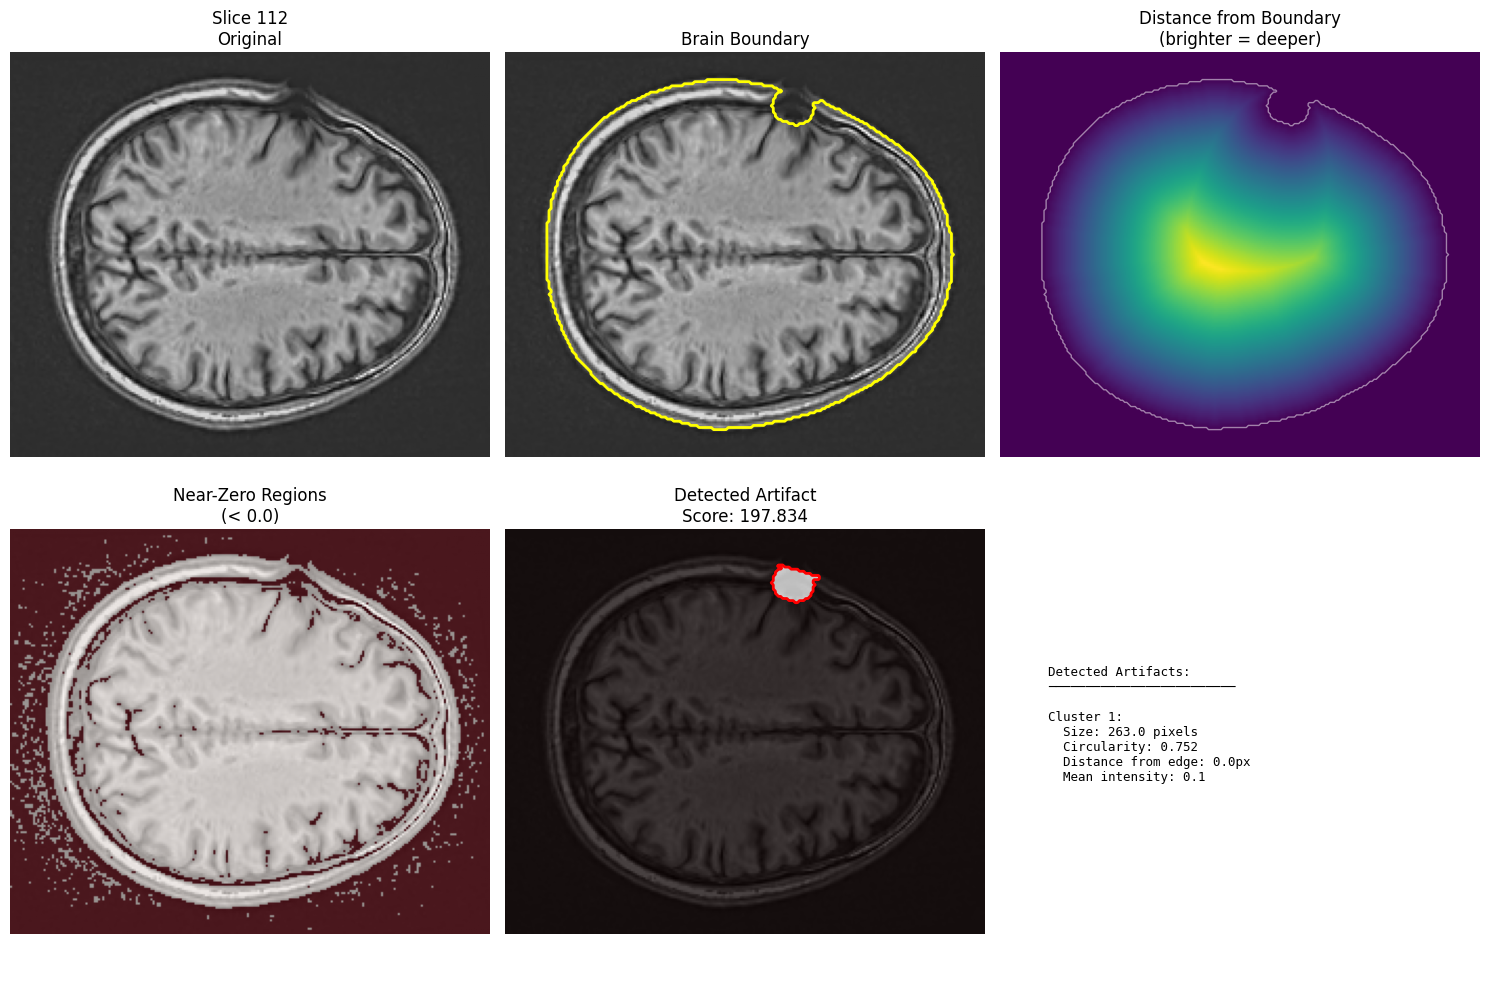

In [ ]:
target_slices = range(0, 192)

# Find anchor
anchor_slice, anchor_info = find_anchor_by_boundary_artifact_detection(
    reg_image.numpy(),
    target_slices,
    axis=2,
    verbose=False
)

# Visualize
img_slice =  reg_image.numpy()[:, :, anchor_slice]

hull = anchor_info['hull_mask']
dent = anchor_info['dent_mask']

visualize_anchor_detection_simple(
    img_slice,
    hull
    #anchor_info['brain_mask'],
    anchor_info['artifact_mask'],
    anchor_slice,
    anchor_info['artifact_score']
)

refined_mask = refine_anchor_mask(anchor_info['artifact_mask'])
anchor_info['artifact_mask'] = refined_mask
anchor_info['size'] = refined_mask.sum()
anchor_info['centroid'] = ndimage.center_of_mass(refined_mask)

print(f"\n✓ Ready to track from anchor slice {anchor_slice}!")

In [29]:
from collections import deque

class Tracker():
    def __init__(self, img_data):
        self.img_data = img_data

    def track_artifact_3d(self, img_data, anchor_slice, anchor_mask, brain_mask_volume=None, axis=2):
        artifact_3d = np.zeros_like(img_data, dtype=bool)
        self._set_slice(artifact_3d, anchor_slice, axis, anchor_mask)

        backward_end = self.track_backward(img_data, anchor_slice, anchor_mask, artifact_3d, brain_mask_volume, axis)
        forward_end  = self.track_forward( img_data, anchor_slice, anchor_mask, artifact_3d, brain_mask_volume, axis)

        # Bidirectional refinement: re-check every tracked slice using both neighbours
        artifact_3d = self.refine_bidirectional(
            img_data, artifact_3d, backward_end, forward_end,
            anchor_slice, brain_mask_volume, axis)

        # Drop isolated spiky voxels — keep only the single largest 3-D connected blob
        artifact_3d = self.keep_largest_component(artifact_3d)

        tracking_info = {
            'anchor_slice':    anchor_slice,
            'start_slice':     backward_end,
            'end_slice':       forward_end,
            'total_slices':    forward_end - backward_end + 1,
            'artifact_volume': artifact_3d.sum()
        }
        return artifact_3d, tracking_info

    def keep_largest_component(self, artifact_3d):
        """Discard everything except the largest 3-D connected component."""
        from scipy.ndimage import label as nd_label
        labeled, n = nd_label(artifact_3d)
        if n == 0:
            return artifact_3d
        sizes = np.bincount(labeled.ravel())
        sizes[0] = 0  # ignore background label
        return labeled == sizes.argmax()

    def refine_bidirectional(self, img_data, artifact_3d, start_slice, end_slice,
        anchor_slice, brain_mask_volume, axis):
        refined = artifact_3d.copy()

        for z in range(start_slice, end_slice + 1):
            if z == anchor_slice:
                continue  # keep anchor fixed

            img_slice  = np.take(img_data, z, axis=axis)
            brain_mask = self._get_brain_mask(img_data, brain_mask_volume, z, axis)
            if brain_mask is None:
                continue

            prev_mask = np.take(refined, z - 1, axis=axis) if z > start_slice else None
            next_mask = np.take(refined, z + 1, axis=axis) if z < end_slice   else None

            neighbors = [m for m in (prev_mask, next_mask) if m is not None and m.any()]
            if not neighbors:
                continue
            combined_ref      = np.logical_or.reduce(neighbors) if len(neighbors) > 1 else neighbors[0]
            expected_centroid = center_of_mass(combined_ref)
            if np.any(np.isnan(expected_centroid)):
                continue

            new_mask, confidence = self.find_artifact_in_slice(
                img_slice, brain_mask, prev_mask, expected_centroid,
                search_radius=30, next_mask=next_mask)

            if new_mask is not None and new_mask.sum() >= 5:
                self._set_slice(refined, z, axis, new_mask)

        return refined

    def track_backward(self, img_data, anchor_slice, anchor_mask, artifact_3d, brain_mask_volume, axis=2):
        # Rolling window of the last 3 masks: their union is the search reference.
        # A single drifted detection no longer corrupts the whole subsequent chain.
        mask_buffer   = deque([anchor_mask.copy()], maxlen=3)
        current_slice = anchor_slice

        for z in range(anchor_slice - 1, -1, -1):
            img_slice  = np.take(img_data, z, axis=axis)
            brain_mask = self._get_brain_mask(img_data, brain_mask_volume, z, axis)
            if brain_mask is None:
                break

            smooth_ref      = np.logical_or.reduce(list(mask_buffer))
            smooth_centroid = center_of_mass(smooth_ref)

            artifact_mask, confidence = self.find_artifact_in_slice(
                img_slice, brain_mask, smooth_ref, smooth_centroid, search_radius=30)

            if artifact_mask is None or artifact_mask.sum() < 5:
                break
            # Validate drift/size against the single most-recent mask, not the smoothed union
            if not self.validate_tracked_artifact(artifact_mask, mask_buffer[-1], img_slice, brain_mask):
                break

            self._set_slice(artifact_3d, z, axis, artifact_mask)
            mask_buffer.append(artifact_mask)
            current_slice = z

        return current_slice

    def track_forward(self, img_data, anchor_slice, anchor_mask, artifact_3d, brain_mask_volume, axis=2):
        n_slices      = img_data.shape[axis]
        mask_buffer   = deque([anchor_mask.copy()], maxlen=3)
        current_slice = anchor_slice

        for z in range(anchor_slice + 1, n_slices):
            img_slice  = np.take(img_data, z, axis=axis)
            brain_mask = self._get_brain_mask(img_data, brain_mask_volume, z, axis)
            if brain_mask is None:
                break

            smooth_ref      = np.logical_or.reduce(list(mask_buffer))
            smooth_centroid = center_of_mass(smooth_ref)

            artifact_mask, confidence = self.find_artifact_in_slice(
                img_slice, brain_mask, smooth_ref, smooth_centroid, search_radius=10)

            if artifact_mask is None or artifact_mask.sum() < 5:
                break
            if not self.validate_tracked_artifact(artifact_mask, mask_buffer[-1], img_slice, brain_mask):
                break

            self._set_slice(artifact_3d, z, axis, artifact_mask)
            mask_buffer.append(artifact_mask)
            current_slice = z

        return current_slice

    def remove_noise(self, img_slice):
        thresh = filters.threshold_otsu(img_slice)
        rough_mask = img_slice > thresh

        cleaned = morphology.binary_closing(rough_mask, morphology.disk(3))
        labels = measure.label(cleaned)
        if labels.max() > 0:
            brain_blob = (labels == (np.argmax(np.bincount(labels.flat)[1:]) + 1))
        else:
            brain_blob = cleaned

        final_brain_mask = ndimage.binary_fill_holes(brain_blob)
        final_brain_mask = morphology.binary_closing(final_brain_mask, morphology.disk(8))

        return np.where(img_slice, final_brain_mask, 0)
        
    def _get_brain_mask(self, img_data, brain_mask_volume, z, axis):
        if brain_mask_volume is not None:
            return np.take(brain_mask_volume, z, axis=axis)
        img_slice = np.take(img_data, z, axis=axis)
        result = self._get_brain_contour(img_slice)
        return result[0] if result is not None else None

    def _get_brain_contour(self, img_slice):
        binary_mask = remove_noise(img_slice)
        
        if binary_mask.sum() < 100:
            return None

        contours = measure.find_contours(binary_mask.astype(float), 0.5)
        
        if len(contours) == 0:
            return None

        largest_contour = max(contours, key=len)
    
        from skimage.draw import polygon
        brain_mask = np.zeros_like(img_slice, dtype=bool)
        rr, cc = polygon(largest_contour[:, 0], largest_contour[:, 1], img_slice.shape)
        brain_mask[rr, cc] = True
        
        return brain_mask, largest_contour

    def _set_slice(self, volume, z, axis, mask):
        if axis == 2:
            volume[:, :, z] = mask
        elif axis == 1:
            volume[:, z, :] = mask
        elif axis == 0:
            volume[z, :, :] = mask

    def find_artifact_in_slice_old(self, img_slice, brain_mask, prev_mask, expected_centroid,
                                search_radius=10, next_mask=None):
        from scipy.ndimage import label, binary_dilation
        from skimage.measure import regionprops

        if brain_mask.sum() == 0:
            return None, 0.0

        hull_mask  = morphology.convex_hull_image(brain_mask)
        dents_mask = hull_mask & ~brain_mask
        dents_mask = morphology.remove_small_objects(dents_mask, min_size=20)

        if dents_mask.sum() == 0:
            return None, 0.0

        spatial_mask = self.create_search_region(brain_mask.shape, expected_centroid, search_radius)

        neighbor_masks = [m for m in (prev_mask, next_mask) if m is not None and m.sum() > 0]
        if neighbor_masks:
            predicted_zone = np.zeros_like(brain_mask, dtype=bool)
            for nm in neighbor_masks:
                predicted_zone |= binary_dilation(nm, iterations=4)
            candidate_zones = dents_mask & spatial_mask #& predicted_zone
            if candidate_zones.sum() == 0:
                candidate_zones = dents_mask & spatial_mask
        else:
            candidate_zones = dents_mask & spatial_mask

        if candidate_zones.sum() == 0:
            return None, 0.0

        labeled, n_components = label(candidate_zones)
        brain_mean = img_slice[brain_mask].mean() if brain_mask.any() else 1.0
        best_cluster, best_score = None, -1.0

        for comp_id in range(1, n_components + 1):
            component = (labeled == comp_id)
            size = component.sum()
            if size < 10 or size > 2000:
                continue

            mean_intensity = img_slice[component].mean()

            # Global gate: at least 20% darker than brain mean
            if mean_intensity > brain_mean * 0.80:
                continue

            # Local contrast gate: darker than immediately adjacent brain tissue
            adjacent_brain = binary_dilation(component, iterations=3) & brain_mask
            if adjacent_brain.any():
                if mean_intensity > img_slice[adjacent_brain].mean() * 0.85:
                    continue

            try:
                props = regionprops(component.astype(int))[0]
            except IndexError:
                continue

            # IoU averaged across all available neighbours
            if neighbor_masks:
                iou_vals = []
                for nm in neighbor_masks:
                    inter = np.logical_and(component, nm).sum()
                    union = np.logical_or(component, nm).sum()
                    iou_vals.append(inter / (union + 1e-6))
                iou_score = float(np.mean(iou_vals))
            else:
                iou_score = 1.0

            dist          = np.linalg.norm(np.array(props.centroid) - np.array(expected_centroid))
            dist_score    = max(0.0, 1.0 - dist / search_radius)
            darkness_score = 1.0 - np.clip(mean_intensity / (brain_mean + 1e-6), 0, 1)

            confidence = (
                0.50 * iou_score                       +
                0.20 * dist_score                      +
                0.15 * min(props.solidity, 0.95)       +
                0.15 * darkness_score
            )

            if confidence > best_score and confidence > 0.25:
                best_score   = confidence
                best_cluster = component

        return best_cluster, best_score

    def find_artifact_in_slice(self, img_slice, brain_mask, prev_mask, expected_centroid,
        search_radius=10, next_mask=None):

        if brain_mask.sum() == 0:
            return None, 0.0

        hull_mask  = morphology.convex_hull_image(brain_mask)
        dents_mask = hull_mask & ~brain_mask

        spatial_mask = self.create_search_region(img_slice.shape, expected_centroid, search_radius)
        target_zone = dents_mask & spatial_mask
        
        if target_zone.sum() == 0:
            return None, 0.0
        
        zone_values = img_slice[target_zone]
        brain_mean = img_slice[brain_mask].mean()
        
        threshold = filters.threshold_otsu(zone_values)
        artifact_pixels_mask = (img_slice <= threshold) & target_zone

        if artifact_pixels_mask.sum() < 3: # Too few pixels to be an artifact
            return None, 0.0
        
        refined_artifact = morphology.binary_opening(artifact_pixels_mask, morphology.disk(1))

        from scipy.ndimage import label
        labeled_regions, num_features = label(refined_artifact)
        
        if num_features == 0:
            return None, 0.0
        elif num_features > 1:
            # If there are multiple dark spots, pick the one closest to the anchor centroid
            best_comp = None
            min_dist = float('inf')
            
            for i in range(1, num_features + 1):
                region_mask = (labeled_regions == i)
                region_com = center_of_mass(region_mask)
                d = np.linalg.norm(np.array(region_com) - np.array(expected_centroid))
                
                # Tie-break: You could also factor in darkness here
                if d < min_dist:
                    min_dist = d
                    best_comp = region_mask
            
            refined_artifact = best_comp
        
        # 5. Score based on Darkest Average
        # A real artifact will have a very low mean intensity
        actual_mean = img_slice[refined_artifact].mean()
        darkness_score = 1.0 - (actual_mean / brain_mean)
        
        # Distance penalty: how far is this new dark cluster from our anchor?
        current_centroid = center_of_mass(refined_artifact)
        dist = np.linalg.norm(np.array(current_centroid) - np.array(expected_centroid))
        dist_score = max(0.0, 1.0 - dist / search_radius)

        # Final confidence: mostly based on how dark it is and how close it is
        confidence = (0.6 * darkness_score) + (0.4 * dist_score)

        return refined_artifact, confidence

    def validate_tracked_artifact(self, current_mask, previous_mask, img_slice, brain_mask, verbose=False):
        if previous_mask is None:
            return True

        drift = np.linalg.norm(
            np.array(center_of_mass(current_mask)) - np.array(center_of_mass(previous_mask)))
        if drift > 5:
            if verbose: print(f"  ✗ centroid drift {drift:.1f}px")
            return False

        size_ratio = current_mask.sum() / (previous_mask.sum() + 1e-6)
        if not (0.3 <= size_ratio <= 2.0):
            if verbose: print(f"  ✗ size ratio {size_ratio:.2f}")
            return False

        return True

    def create_search_region(self, shape, center, radius):
        Y, X = np.ogrid[:shape[0], :shape[1]]
        cy, cx = center
        return (np.sqrt((Y - cy)**2 + (X - cx)**2) <= radius)

def visualize_tracking_montage(img_data, artifact_3d, tracking_info, axis=2):
    import matplotlib.pyplot as plt

    start_slice  = tracking_info['start_slice']
    end_slice    = tracking_info['end_slice']
    anchor_slice = tracking_info['anchor_slice']
    n_slices     = end_slice - start_slice + 1

    n_cols = min(5, n_slices)
    n_rows = int(np.ceil(n_slices / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = axes.flatten() if n_slices > 1 else [axes]

    for idx, z in enumerate(range(start_slice, end_slice + 1)):
        if idx >= len(axes):
            break
        img_slice      = np.take(img_data, z, axis=axis)
        artifact_slice = np.take(artifact_3d, z, axis=axis)

        axes[idx].imshow(img_slice, cmap='gray')
        if artifact_slice.any():
            axes[idx].contour(artifact_slice, levels=[0.5], colors='red', linewidths=1.5)

        title = f'Slice {z}\n⭐ ANCHOR' if z == anchor_slice else f'Slice {z}'
        color = 'red' if z == anchor_slice else 'white'
        axes[idx].set_title(title, fontsize=9, color=color,
                            fontweight='bold' if z == anchor_slice else 'normal')
        axes[idx].axis('off')

    for idx in range(n_slices, len(axes)):
        axes[idx].axis('off')

    plt.suptitle(f'Tracked Artifact: Slices {start_slice}–{end_slice}',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('tracking_montage.png', dpi=150, bbox_inches='tight')
    print("✓ Saved: tracking_montage.png")
    plt.show()

def create_tracking_animation(img_data, artifact_3d, tracking_info, axis=2, fps=2):
    import matplotlib.pyplot as plt
    import matplotlib.animation as animation
    from matplotlib.animation import PillowWriter

    start_slice  = tracking_info['start_slice']
    end_slice    = tracking_info['end_slice']
    anchor_slice = tracking_info['anchor_slice']

    fig, ax = plt.subplots(figsize=(8, 8))

    def update(z):
        ax.clear()
        img_slice      = np.take(img_data, z, axis=axis)
        artifact_slice = np.take(artifact_3d, z, axis=axis)

        ax.imshow(img_slice, cmap='gray')
        if artifact_slice.any():
            ax.contour(artifact_slice, levels=[0.5], colors='red', linewidths=2)

        title = f'Slice {z} ⭐ ANCHOR' if z == anchor_slice else f'Slice {z}'
        ax.set_title(title, fontsize=14,
                     fontweight='bold' if z == anchor_slice else 'normal',
                     color='red' if z == anchor_slice else 'white')
        ax.axis('off')

        progress = (z - start_slice) / max(end_slice - start_slice, 1)
        ax.text(0.5, 0.02, f'Progress: {progress*100:.0f}%',
                transform=ax.transAxes, ha='center', fontsize=12,
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    anim = animation.FuncAnimation(
        fig, update,
        frames=range(start_slice, end_slice + 1),
        interval=1000 / fps, repeat=True
    )
    writer = PillowWriter(fps=fps)
    anim.save('tracking_animation.gif', writer=writer)
    print("✓ Saved: tracking_animation.gif")
    plt.close()

def visualize_3d_surface(img_data, artifact_3d, tracking_info):
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D
    from skimage import measure

    try:
        verts, faces, _, _ = measure.marching_cubes(artifact_3d.astype(float), level=0.5)
    except Exception as e:
        print(f"Could not generate 3D surface: {e}")
        return

    fig = plt.figure(figsize=(12, 10))
    ax  = fig.add_subplot(111, projection='3d')
    ax.plot_trisurf(verts[:, 0], verts[:, 1], faces, verts[:, 2],
                    cmap='hot', alpha=0.8, edgecolor='darkred', linewidth=0.1)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z (slice)')
    ax.set_title('3D Tracked Artifact', fontsize=14, fontweight='bold')
    ax.view_init(elev=20, azim=45)
    plt.tight_layout()
    plt.savefig('tracking_3d_surface.png', dpi=150, bbox_inches='tight')
    print("✓ Saved: tracking_3d_surface.png")
    plt.show()

def plot_tracking_statistics(img_data, artifact_3d, tracking_info, axis=2):
    import matplotlib.pyplot as plt
    from skimage.measure import regionprops

    start_slice  = tracking_info['start_slice']
    end_slice    = tracking_info['end_slice']
    anchor_slice = tracking_info['anchor_slice']
    slices       = list(range(start_slice, end_slice + 1))

    sizes, circularities, mean_intensities = [], [], []
    centroids_x, centroids_y = [], []

    for z in slices:
        artifact_slice = np.take(artifact_3d, z, axis=axis)
        img_slice      = np.take(img_data,    z, axis=axis)

        if artifact_slice.sum() == 0:
            sizes.append(0); circularities.append(0)
            mean_intensities.append(0); centroids_x.append(0); centroids_y.append(0)
            continue

        sizes.append(artifact_slice.sum())
        props = regionprops(artifact_slice.astype(int))
        if props:
            p = props[0]
            circ = (4 * np.pi * p.area) / (p.perimeter ** 2) if p.perimeter > 0 else 0
            circularities.append(min(circ, 1.0))
            centroids_y.append(p.centroid[0]); centroids_x.append(p.centroid[1])
        else:
            circularities.append(0); centroids_x.append(0); centroids_y.append(0)
        mean_intensities.append(img_slice[artifact_slice].mean())

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    axes[0, 0].plot(slices, sizes, 'b-o', linewidth=2, markersize=5)
    axes[0, 0].axvline(anchor_slice, color='red', linestyle='--', linewidth=2, label='Anchor')
    axes[0, 0].set(xlabel='Slice', ylabel='Size (px)', title='Artifact Size'); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

    axes[0, 1].plot(slices, circularities, 'g-o', linewidth=2, markersize=5)
    axes[0, 1].axvline(anchor_slice, color='red', linestyle='--', linewidth=2, label='Anchor')
    axes[0, 1].set(xlabel='Slice', ylabel='Circularity', title='Artifact Circularity', ylim=[0, 1.1]); axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

    axes[1, 0].plot(slices, mean_intensities, 'r-o', linewidth=2, markersize=5)
    axes[1, 0].axvline(anchor_slice, color='red', linestyle='--', linewidth=2, label='Anchor')
    axes[1, 0].set(xlabel='Slice', ylabel='Mean Intensity', title='Artifact Intensity'); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

    axes[1, 1].plot(centroids_x, centroids_y, 'purple', linewidth=2, marker='o', markersize=5)
    ai = anchor_slice - start_slice
    if 0 <= ai < len(centroids_x):
        axes[1, 1].plot(centroids_x[ai], centroids_y[ai], 'r*', markersize=18, label='Anchor')
    axes[1, 1].plot(centroids_x[0],  centroids_y[0],  'go', markersize=10, label='Start')
    axes[1, 1].plot(centroids_x[-1], centroids_y[-1], 'bs', markersize=10, label='End')
    axes[1, 1].set(xlabel='X (px)', ylabel='Y (px)', title='Centroid Trajectory')
    axes[1, 1].invert_yaxis(); axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

    plt.suptitle(f'Tracking Statistics (Slices {start_slice}–{end_slice})',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('tracking_statistics.png', dpi=150, bbox_inches='tight')
    print("✓ Saved: tracking_statistics.png")
    plt.show()

def visualize_before_after(img_data, artifact_3d, tracking_info, axis=2, num_slices=5):
    import matplotlib.pyplot as plt

    start_slice  = tracking_info['start_slice']
    end_slice    = tracking_info['end_slice']
    anchor_slice = tracking_info['anchor_slice']
    total        = end_slice - start_slice + 1

    if total <= num_slices:
        selected = list(range(start_slice, end_slice + 1))
    else:
        step     = total // (num_slices - 1)
        selected = [start_slice + i * step for i in range(num_slices - 1)] + [end_slice]
    if anchor_slice not in selected:
        selected[len(selected) // 2] = anchor_slice
    selected = sorted(selected)

    fig, axes = plt.subplots(len(selected), 2, figsize=(10, 4 * len(selected)))
    if len(selected) == 1:
        axes = axes.reshape(1, -1)

    for idx, z in enumerate(selected):
        img_slice      = np.take(img_data, z, axis=axis)
        artifact_slice = np.take(artifact_3d, z, axis=axis)

        axes[idx, 0].imshow(img_slice, cmap='gray')
        label_text = f'Slice {z} ⭐ ANCHOR' if z == anchor_slice else f'Slice {z}'
        axes[idx, 0].set_title(label_text + ' (Original)',
                                color='red' if z == anchor_slice else 'black')
        axes[idx, 0].axis('off')

        axes[idx, 1].imshow(img_slice, cmap='gray')
        if artifact_slice.any():
            axes[idx, 1].contour(artifact_slice, levels=[0.5], colors='red', linewidths=2)
        axes[idx, 1].set_title(f'Slice {z} (Tracked Artifact)')
        axes[idx, 1].axis('off')

    plt.tight_layout()
    plt.savefig('tracking_before_after.png', dpi=150, bbox_inches='tight')
    print("✓ Saved: tracking_before_after.png")
    plt.show()

def create_interactive_3d_viewer(img_data, artifact_3d):
    try:
        import plotly.graph_objects as go
        from skimage import measure
    except ImportError:
        print("Please install plotly: pip install plotly")
        return

    verts, faces, _, _ = measure.marching_cubes(artifact_3d.astype(float), level=0.5)
    fig = go.Figure(data=[go.Mesh3d(
        x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        color='red', opacity=0.7
    )])
    fig.update_layout(
        title='Interactive 3D Tracked Artifact',
        scene=dict(xaxis_title='X', yaxis_title='Y', zaxis_title='Z (slices)',
                   aspectmode='data'),
        width=900, height=700
    )
    fig.write_html('tracking_interactive_3d.html')
    print("✓ Saved: tracking_interactive_3d.html")

def visualize_all_tracking_results(img_data, artifact_3d, tracking_info, axis=2):
    print("\n" + "="*60)
    print("GENERATING TRACKING VISUALIZATIONS")
    print("="*60 + "\n")

    print("1. Slice montage...")
    visualize_tracking_montage(img_data, artifact_3d, tracking_info, axis)

    print("\n2. Animation...")
    create_tracking_animation(img_data, artifact_3d, tracking_info, axis, fps=2)

    print("\n3. 3D surface...")
    visualize_3d_surface(img_data, artifact_3d, tracking_info)

    print("\n4. Statistics...")
    plot_tracking_statistics(img_data, artifact_3d, tracking_info, axis)

    print("\n5. Before/After...")
    visualize_before_after(img_data, artifact_3d, tracking_info, axis, num_slices=5)

    print("\n6. Interactive 3D...")
    create_interactive_3d_viewer(img_data, artifact_3d)

    print("\n✓ ALL VISUALIZATIONS COMPLETE")
    print("  tracking_montage.png / tracking_animation.gif / tracking_3d_surface.png")
    print("  tracking_statistics.png / tracking_before_after.png / tracking_interactive_3d.html")


In [30]:
import numpy as np
from scipy.ndimage import center_of_mass, label as nd_label
import matplotlib.pyplot as plt


def find_coronal_anchor(artifact_3d_axial):
    """
    Pick the coronal slice (axis=1, Y) with the most axial-detected artifact voxels.
    Volume shape is (X, Y, Z): sum over X (0) and Z (2) → count per Y slice.
    Returns (slice_index, 2D mask of shape (X, Z)).
    """
    counts = artifact_3d_axial.sum(axis=(0, 2))   # shape: (Y,)
    if counts.max() == 0:
        raise ValueError("artifact_3d_axial is empty — run axial tracking first.")
    idx  = int(counts.argmax())
    mask = artifact_3d_axial[:, idx, :].astype(bool)   # shape: (X, Z)
    return idx, mask


def find_sagittal_anchor(artifact_3d_combined):
    """
    Pick the sagittal slice (axis=0, X) with the most combined artifact voxels.
    Volume shape is (X, Y, Z): sum over Y (1) and Z (2) → count per X slice.
    Returns (slice_index, 2D mask of shape (Y, Z)).
    """
    counts = artifact_3d_combined.sum(axis=(1, 2))   # shape: (X,)
    if counts.max() == 0:
        raise ValueError("artifact_3d_combined is empty — run axial+coronal first.")
    idx  = int(counts.argmax())
    mask = artifact_3d_combined[idx, :, :].astype(bool)   # shape: (Y, Z)
    return idx, mask


def keep_largest_component(artifact_3d):
    """
    Discard everything except the largest 3-D connected component.
    """
    labeled, n = nd_label(artifact_3d)
    if n == 0:
        return artifact_3d
    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0  # ignore background label
    return labeled == sizes.argmax()


def track_coronal(tracker, img_data, artifact_3d_axial, brain_mask_volume=None):
    """
    Seed coronal tracking (axis=1) from the axial 3-D result.
    The anchor is the coronal slice (Y) richest in axial-detected voxels.
    Returns (artifact_3d_coronal, tracking_info).
    """
    anchor_idx, anchor_mask = find_coronal_anchor(artifact_3d_axial)
    print(f"\n{'='*80}")
    print(f"CORONAL TRACKING (Axis=1, Y slices)")
    print(f"{'='*80}")
    print(f"Coronal anchor: Y slice = {anchor_idx}")
    print(f"Seed pixels: {anchor_mask.sum()}")
    
    # Optional: refine the anchor mask if you have that function
    # anchor_mask = refine_anchor_mask(anchor_mask)
    
    artifact_3d_coronal, info = tracker.track_artifact_3d(
        img_data, anchor_idx, anchor_mask,
        brain_mask_volume, axis=1
    )
    
    info['plane'] = 'coronal'
    print(f"Coronal slices tracked: {info['start_slice']} → {info['end_slice']}")
    print(f"Coronal volume: {info['artifact_volume']} voxels")
    
    return artifact_3d_coronal, info


def track_sagittal(tracker, img_data, artifact_3d_combined, brain_mask_volume=None):
    """
    Seed sagittal tracking (axis=0) from the combined axial+coronal 3-D result.
    The anchor is the sagittal slice (X) richest in combined voxels.
    Returns (artifact_3d_sagittal, tracking_info).
    """
    anchor_idx, anchor_mask = find_sagittal_anchor(artifact_3d_combined)
    print(f"\n{'='*80}")
    print(f"SAGITTAL TRACKING (Axis=0, X slices)")
    print(f"{'='*80}")
    print(f"Sagittal anchor: X slice = {anchor_idx}")
    print(f"Seed pixels: {anchor_mask.sum()}")
    
    # Optional: refine the anchor mask if you have that function
    # anchor_mask = refine_anchor_mask(anchor_mask)
    
    artifact_3d_sagittal, info = tracker.track_artifact_3d(
        img_data, anchor_idx, anchor_mask,
        brain_mask_volume, axis=0
    )
    
    info['plane'] = 'sagittal'
    print(f"Sagittal slices tracked: {info['start_slice']} → {info['end_slice']}")
    print(f"Sagittal volume: {info['artifact_volume']} voxels")
    
    return artifact_3d_sagittal, info


def combine_planes(*artifact_volumes):
    """
    Union of multiple plane results, then keep the largest 3-D connected
    component so stray false positives from any plane don't survive the merge.
    
    Args:
        *artifact_volumes: Variable number of 3D binary masks
        
    Returns:
        Combined 3D binary mask with only largest connected component
    """
    # Union of all planes
    combined = np.zeros_like(artifact_volumes[0], dtype=bool)
    for artifact in artifact_volumes:
        combined |= artifact
    
    # Keep only largest component
    return keep_largest_component(combined)


def visualize_multiplanar(img_data, artifact_combined, axial_info, 
                          coronal_info, sagittal_info):
    """
    Show the anchor slice from each plane plus cross-sections through
    the artifact centroid.
    """
    fig = plt.figure(figsize=(20, 12))
    gs = fig.add_gridspec(3, 4, hspace=0.3, wspace=0.3)
    
    # Row 1: Anchor slices from each plane
    print("\nVisualizing multi-planar results...")
    
    # Axial anchor
    ax1 = fig.add_subplot(gs[0, 0])
    axial_slice = axial_info['anchor_slice']
    img_slice = np.take(img_data, axial_slice, axis=2)
    artifact_slice = np.take(artifact_combined, axial_slice, axis=2)
    ax1.imshow(img_slice, cmap='gray')
    if artifact_slice.any():
        ax1.contour(artifact_slice, levels=[0.5], colors='red', linewidths=2)
    ax1.set_title(f'AXIAL Anchor\n(Z={axial_slice})', fontweight='bold')
    ax1.axis('off')
    
    # Coronal anchor
    ax2 = fig.add_subplot(gs[0, 1])
    coronal_slice = coronal_info['anchor_slice']
    img_slice = np.take(img_data, coronal_slice, axis=1)
    artifact_slice = np.take(artifact_combined, coronal_slice, axis=1)
    ax2.imshow(img_slice, cmap='gray')
    if artifact_slice.any():
        ax2.contour(artifact_slice, levels=[0.5], colors='red', linewidths=2)
    ax2.set_title(f'CORONAL Anchor\n(Y={coronal_slice})', fontweight='bold')
    ax2.axis('off')
    
    # Sagittal anchor
    ax3 = fig.add_subplot(gs[0, 2])
    sagittal_slice = sagittal_info['anchor_slice']
    img_slice = np.take(img_data, sagittal_slice, axis=0)
    artifact_slice = np.take(artifact_combined, sagittal_slice, axis=0)
    ax3.imshow(img_slice, cmap='gray')
    if artifact_slice.any():
        ax3.contour(artifact_slice, levels=[0.5], colors='red', linewidths=2)
    ax3.set_title(f'SAGITTAL Anchor\n(X={sagittal_slice})', fontweight='bold')
    ax3.axis('off')
    
    # Summary statistics
    ax4 = fig.add_subplot(gs[0, 3])
    stats_text = (
        "MULTI-PLANAR TRACKING SUMMARY\n"
        "=" * 35 + "\n\n"
        f"Axial Tracking:\n"
        f"  Slices: {axial_info['start_slice']} → {axial_info['end_slice']}\n"
        f"  Volume: {axial_info['artifact_volume']} voxels\n\n"
        f"Coronal Tracking:\n"
        f"  Slices: {coronal_info['start_slice']} → {coronal_info['end_slice']}\n"
        f"  Volume: {coronal_info['artifact_volume']} voxels\n\n"
        f"Sagittal Tracking:\n"
        f"  Slices: {sagittal_info['start_slice']} → {sagittal_info['end_slice']}\n"
        f"  Volume: {sagittal_info['artifact_volume']} voxels\n\n"
        f"Combined Volume:\n"
        f"  Total: {artifact_combined.sum()} voxels\n"
        f"  Improvement: {artifact_combined.sum() / axial_info['artifact_volume']:.2f}x\n"
    )
    ax4.text(0.05, 0.95, stats_text, 
            fontsize=9, family='monospace',
            verticalalignment='top',
            transform=ax4.transAxes)
    ax4.axis('off')
    
    # Row 2: Cross-sections through artifact centroid
    if artifact_combined.sum() > 0:
        # Find centroid of combined artifact
        centroid = center_of_mass(artifact_combined)
        cx, cy, cz = [int(c) for c in centroid]
        
        # Axial cross-section at centroid
        ax5 = fig.add_subplot(gs[1, 0])
        img_slice = img_data[:, :, cz]
        artifact_slice = artifact_combined[:, :, cz]
        ax5.imshow(img_slice, cmap='gray')
        if artifact_slice.any():
            ax5.contour(artifact_slice, levels=[0.5], colors='cyan', linewidths=2)
            ax5.plot(cy, cx, 'y+', markersize=20, markeredgewidth=3)
        ax5.set_title(f'Axial @ Centroid\n(Z={cz})')
        ax5.axis('off')
        
        # Coronal cross-section at centroid
        ax6 = fig.add_subplot(gs[1, 1])
        img_slice = img_data[:, cy, :]
        artifact_slice = artifact_combined[:, cy, :]
        ax6.imshow(img_slice, cmap='gray')
        if artifact_slice.any():
            ax6.contour(artifact_slice, levels=[0.5], colors='cyan', linewidths=2)
            ax6.plot(cz, cx, 'y+', markersize=20, markeredgewidth=3)
        ax6.set_title(f'Coronal @ Centroid\n(Y={cy})')
        ax6.axis('off')
        
        # Sagittal cross-section at centroid
        ax7 = fig.add_subplot(gs[1, 2])
        img_slice = img_data[cx, :, :]
        artifact_slice = artifact_combined[cx, :, :]
        ax7.imshow(img_slice, cmap='gray')
        if artifact_slice.any():
            ax7.contour(artifact_slice, levels=[0.5], colors='cyan', linewidths=2)
            ax7.plot(cz, cy, 'y+', markersize=20, markeredgewidth=3)
        ax7.set_title(f'Sagittal @ Centroid\n(X={cx})')
        ax7.axis('off')
        
        # 3D representation (text-based)
        ax8 = fig.add_subplot(gs[1, 3])
        extent_text = (
            "3D ARTIFACT EXTENT\n"
            "=" * 30 + "\n\n"
            f"Centroid: ({cx}, {cy}, {cz})\n\n"
            f"X range: {sagittal_info['start_slice']} → {sagittal_info['end_slice']}\n"
            f"  Span: {sagittal_info['total_slices']} slices\n\n"
            f"Y range: {coronal_info['start_slice']} → {coronal_info['end_slice']}\n"
            f"  Span: {coronal_info['total_slices']} slices\n\n"
            f"Z range: {axial_info['start_slice']} → {axial_info['end_slice']}\n"
            f"  Span: {axial_info['total_slices']} slices\n\n"
            f"Bounding box:\n"
            f"  {sagittal_info['total_slices']} × "
            f"{coronal_info['total_slices']} × "
            f"{axial_info['total_slices']}\n"
        )
        ax8.text(0.05, 0.95, extent_text,
                fontsize=9, family='monospace',
                verticalalignment='top',
                transform=ax8.transAxes)
        ax8.axis('off')
    
    # Row 3: Volume comparison across planes
    ax9 = fig.add_subplot(gs[2, :2])
    planes = ['Axial\nOnly', 'Axial+\nCoronal', 'Axial+Coronal+\nSagittal\n(Final)']
    
    # Calculate intermediate volumes
    axial_only = axial_info['artifact_volume']
    axial_coronal = keep_largest_component(
        artifact_combined | np.zeros_like(artifact_combined)
    ).sum() if 'artifact_coronal' in locals() else axial_only
    final_volume = artifact_combined.sum()
    
    volumes = [axial_only, axial_coronal, final_volume]
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
    
    bars = ax9.bar(planes, volumes, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
    ax9.set_ylabel('Artifact Volume (voxels)', fontsize=11)
    ax9.set_title('Progressive Refinement Across Planes', fontsize=12, fontweight='bold')
    ax9.grid(axis='y', alpha=0.3)
    
    # Add value labels on bars
    for bar, vol in zip(bars, volumes):
        height = bar.get_height()
        ax9.text(bar.get_x() + bar.get_width()/2., height,
                f'{int(vol)}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Plane comparison table
    ax10 = fig.add_subplot(gs[2, 2:])
    table_data = [
        ['Plane', 'Axis', 'Anchor Slice', 'Slice Range', 'Volume'],
        ['Axial', '2 (Z)', str(axial_info['anchor_slice']), 
         f"{axial_info['start_slice']}-{axial_info['end_slice']}", 
         str(axial_info['artifact_volume'])],
        ['Coronal', '1 (Y)', str(coronal_info['anchor_slice']),
         f"{coronal_info['start_slice']}-{coronal_info['end_slice']}",
         str(coronal_info['artifact_volume'])],
        ['Sagittal', '0 (X)', str(sagittal_info['anchor_slice']),
         f"{sagittal_info['start_slice']}-{sagittal_info['end_slice']}",
         str(sagittal_info['artifact_volume'])],
        ['Combined', '—', '—', '—', str(artifact_combined.sum())]
    ]
    
    table = ax10.table(cellText=table_data, cellLoc='center',
                      colWidths=[0.2, 0.15, 0.2, 0.25, 0.2],
                      loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 2)
    
    # Style header row
    for i in range(5):
        table[(0, i)].set_facecolor('#34495e')
        table[(0, i)].set_text_props(weight='bold', color='white')
    
    # Style data rows
    for i in range(1, 5):
        for j in range(5):
            if i == 4:  # Combined row
                table[(i, j)].set_facecolor('#95a5a6')
                table[(i, j)].set_text_props(weight='bold')
            else:
                table[(i, j)].set_facecolor('#ecf0f1' if i % 2 == 0 else 'white')
    
    ax10.axis('off')
    
    plt.suptitle('Multi-Planar Catheter Artifact Tracking Results', 
                 fontsize=16, fontweight='bold', y=0.98)
    
    plt.savefig('multiplanar_tracking_results.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Saved: multiplanar_tracking_results.png")


def run_complete_multiplanar_tracking(tracker, img_data, axial_anchor_slice, 
                                     axial_anchor_mask, brain_mask_volume=None):
    """
    Complete multi-planar tracking pipeline: Axial → Coronal → Sagittal.
    
    Args:
        tracker: ImprovedTracker instance
        img_data: 3D image volume (X, Y, Z)
        axial_anchor_slice: Initial anchor slice index for axial
        axial_anchor_mask: Initial anchor mask for axial
        brain_mask_volume: Optional pre-computed brain masks
        
    Returns:
        artifact_combined: Final combined 3D artifact mask
        tracking_results: Dict with all tracking info
    """
    
    print("=" * 80)
    print("MULTI-PLANAR CATHETER ARTIFACT TRACKING")
    print("=" * 80)
    
    # STEP 1: Axial tracking (primary)
    print(f"\n{'='*80}")
    print(f"STEP 1: AXIAL TRACKING (Axis=2, Z slices)")
    print(f"{'='*80}")
    print(f"Axial anchor: Z slice = {axial_anchor_slice}")
    print(f"Seed pixels: {axial_anchor_mask.sum()}")
    
    artifact_3d_axial, axial_info = tracker.track_artifact_3d(
        img_data, axial_anchor_slice, axial_anchor_mask,
        brain_mask_volume, axis=2
    )
    axial_info['plane'] = 'axial'
    print(f"Axial slices tracked: {axial_info['start_slice']} → {axial_info['end_slice']}")
    print(f"Axial volume: {axial_info['artifact_volume']} voxels")
    
    # STEP 2: Coronal tracking (seeded from axial)
    artifact_3d_coronal, coronal_info = track_coronal(
        tracker, img_data, artifact_3d_axial, brain_mask_volume
    )
    
    # Combine axial + coronal
    artifact_axial_coronal = combine_planes(artifact_3d_axial, artifact_3d_coronal)
    print(f"\nAxial + Coronal combined: {artifact_axial_coronal.sum()} voxels")
    
    # STEP 3: Sagittal tracking (seeded from combined axial+coronal)
    artifact_3d_sagittal, sagittal_info = track_sagittal(
        tracker, img_data, artifact_axial_coronal, brain_mask_volume
    )
    
    # STEP 4: Final combination of all three planes
    print(f"\n{'='*80}")
    print("STEP 4: FINAL COMBINATION")
    print(f"{'='*80}")
    artifact_combined = combine_planes(
        artifact_3d_axial, artifact_3d_coronal, artifact_3d_sagittal
    )
    print(f"Final combined volume: {artifact_combined.sum()} voxels")
    print(f"Improvement over axial-only: {artifact_combined.sum() / axial_info['artifact_volume']:.2f}x")
    
    tracking_results = {
        'axial': (artifact_3d_axial, axial_info),
        'coronal': (artifact_3d_coronal, coronal_info),
        'sagittal': (artifact_3d_sagittal, sagittal_info),
        'combined': artifact_combined
    }
    
    return artifact_combined, tracking_results



In [31]:
tracker = Tracker(reg_image.numpy())

artifact_combined, tracking_results = run_complete_multiplanar_tracking(tracker, reg_image.numpy(), anchor_slice, 
                                     anchor_info['artifact_mask'], brain_mask_volume=None)

MULTI-PLANAR CATHETER ARTIFACT TRACKING

STEP 1: AXIAL TRACKING (Axis=2, Z slices)
Axial anchor: Z slice = 112
Seed pixels: 231
Axial slices tracked: 102 → 112
Axial volume: 2121 voxels

CORONAL TRACKING (Axis=1, Y slices)
Coronal anchor: Y slice = 133
Seed pixels: 147
Coronal slices tracked: 131 → 145
Coronal volume: 2807 voxels

Axial + Coronal combined: 3192 voxels

SAGITTAL TRACKING (Axis=0, X slices)
Sagittal anchor: X slice = 25
Seed pixels: 317
Sagittal slices tracked: 25 → 25
Sagittal volume: 317 voxels

STEP 4: FINAL COMBINATION
Final combined volume: 3192 voxels
Improvement over axial-only: 1.50x


In [18]:
import numpy as np
from scipy.ndimage import center_of_mass, label as nd_label
import matplotlib.pyplot as plt


def find_all_sagittal_slices_with_artifact(artifact_3d_combined, min_voxels=10):
    """
    Find ALL sagittal slices (X axis) that contain artifact voxels.
    
    Instead of picking one "best" anchor, this identifies every X slice
    that has artifact, so we can track through all of them.
    
    Args:
        artifact_3d_combined: 3D binary mask from axial+coronal tracking
        min_voxels: Minimum number of voxels to consider a slice valid
        
    Returns:
        valid_slices: List of (slice_index, 2D_mask, voxel_count) tuples
    """
    # Volume shape: (X, Y, Z)
    # Count voxels per X slice
    counts = artifact_3d_combined.sum(axis=(1, 2))  # shape: (X,)
    
    if counts.max() == 0:
        raise ValueError("artifact_3d_combined is empty!")
    
    valid_slices = []
    
    for x_idx in range(len(counts)):
        voxel_count = counts[x_idx]
        
        if voxel_count >= min_voxels:
            # Extract 2D mask for this X slice
            mask_2d = artifact_3d_combined[x_idx, :, :].astype(bool)  # shape: (Y, Z)
            
            valid_slices.append({
                'slice_index': x_idx,
                'mask': mask_2d,
                'voxel_count': int(voxel_count)
            })
    
    print(f"\nFound {len(valid_slices)} sagittal slices with artifact:")
    print(f"  X range: {valid_slices[0]['slice_index']} → {valid_slices[-1]['slice_index']}")
    print(f"  Total span: {valid_slices[-1]['slice_index'] - valid_slices[0]['slice_index'] + 1} slices")
    print(f"  Voxel counts: {min([s['voxel_count'] for s in valid_slices])} to {max([s['voxel_count'] for s in valid_slices])}")
    
    return valid_slices


def track_sagittal_multianchor(tracker, img_data, artifact_3d_combined, 
                               brain_mask_volume=None, min_voxels=10,
                               verbose=True):
    """
    Track in sagittal plane using MULTIPLE anchors - one for each X slice
    that contains artifact from the combined axial+coronal result.
    
    This is better than single-anchor because:
    - Covers the entire artifact extent in X direction
    - Each slice gets its own tracking (more robust)
    - No single point of failure
    
    Args:
        tracker: ImprovedTracker instance
        img_data: 3D image volume
        artifact_3d_combined: Combined result from axial+coronal
        brain_mask_volume: Optional pre-computed brain masks
        min_voxels: Minimum voxels per slice to track
        verbose: Print progress
        
    Returns:
        artifact_3d_sagittal: Combined sagittal tracking result
        tracking_info: Dictionary with tracking statistics
    """
    
    print(f"\n{'='*80}")
    print(f"MULTI-ANCHOR SAGITTAL TRACKING (Axis=0, X slices)")
    print(f"{'='*80}")
    
    # Find all valid sagittal slices
    valid_slices = find_all_sagittal_slices_with_artifact(
        artifact_3d_combined, min_voxels
    )
    
    if len(valid_slices) == 0:
        raise ValueError("No valid sagittal slices found!")
    
    # Initialize result volume
    artifact_3d_sagittal = np.zeros_like(img_data, dtype=bool)
    
    # Track statistics
    successful_tracks = 0
    failed_tracks = 0
    total_voxels_added = 0
    
    if verbose:
        print(f"\nTracking through {len(valid_slices)} sagittal slices...")
        print("-" * 80)
    
    # Track from each valid slice
    for i, slice_info in enumerate(valid_slices):
        x_idx = slice_info['slice_index']
        anchor_mask = slice_info['mask']
        
        if verbose and (i % 5 == 0 or i == len(valid_slices) - 1):
            print(f"  [{i+1}/{len(valid_slices)}] X={x_idx:3d}  "
                  f"anchor_voxels={slice_info['voxel_count']:4d}", end="")
        
        try:
            # Track from this slice
            artifact_temp, info = tracker.track_artifact_3d(
                img_data, 
                anchor_slice=x_idx,
                anchor_mask=anchor_mask,
                brain_mask_volume=brain_mask_volume,
                axis=0  # Sagittal
            )
            
            # Accumulate results
            artifact_3d_sagittal |= artifact_temp
            
            voxels_in_track = artifact_temp.sum()
            total_voxels_added += voxels_in_track
            successful_tracks += 1
            
            if verbose and (i % 5 == 0 or i == len(valid_slices) - 1):
                print(f"  → tracked {info['total_slices']:2d} slices, "
                      f"{voxels_in_track:4d} voxels")
        
        except Exception as e:
            failed_tracks += 1
            if verbose and (i % 5 == 0 or i == len(valid_slices) - 1):
                print(f"  → FAILED: {str(e)[:30]}")
    
    # Clean up: keep only largest component
    artifact_3d_sagittal = keep_largest_component(artifact_3d_sagittal)
    
    # Compile statistics
    tracking_info = {
        'plane': 'sagittal_multianchor',
        'num_anchors': len(valid_slices),
        'successful_tracks': successful_tracks,
        'failed_tracks': failed_tracks,
        'start_slice': valid_slices[0]['slice_index'],
        'end_slice': valid_slices[-1]['slice_index'],
        'total_slices': valid_slices[-1]['slice_index'] - valid_slices[0]['slice_index'] + 1,
        'artifact_volume': int(artifact_3d_sagittal.sum()),
        'anchor_slice': valid_slices[len(valid_slices)//2]['slice_index']  # Middle for visualization
    }
    
    print(f"\n{'='*80}")
    print(f"SAGITTAL MULTI-ANCHOR RESULTS:")
    print(f"{'='*80}")
    print(f"  Anchors used:       {tracking_info['num_anchors']}")
    print(f"  Successful tracks:  {successful_tracks}")
    print(f"  Failed tracks:      {failed_tracks}")
    print(f"  X slice range:      {tracking_info['start_slice']} → {tracking_info['end_slice']}")
    print(f"  Total X span:       {tracking_info['total_slices']} slices")
    print(f"  Final volume:       {tracking_info['artifact_volume']} voxels")
    
    return artifact_3d_sagittal, tracking_info


def track_sagittal_bidirectional_multianchor(tracker, img_data, artifact_3d_combined,
                                            brain_mask_volume=None, min_voxels=10,
                                            verbose=True):
    """
    Even better approach: For each valid X slice, track BOTH forward and backward.
    
    This ensures complete coverage even if some slices fail to track in one direction.
    
    Strategy:
    1. Find all X slices with artifact
    2. For each slice:
       - Track forward (increasing X)
       - Track backward (decreasing X)
    3. Combine all results
    4. Keep largest component
    """
    
    print(f"\n{'='*80}")
    print(f"BIDIRECTIONAL MULTI-ANCHOR SAGITTAL TRACKING")
    print(f"{'='*80}")
    
    # Find all valid sagittal slices
    valid_slices = find_all_sagittal_slices_with_artifact(
        artifact_3d_combined, min_voxels
    )
    
    if len(valid_slices) == 0:
        raise ValueError("No valid sagittal slices found!")
    
    # Initialize result volume
    artifact_3d_sagittal = np.zeros_like(img_data, dtype=bool)
    
    # Start from middle slice (most reliable)
    mid_idx = len(valid_slices) // 2
    
    if verbose:
        print(f"\nStarting from middle slice: X={valid_slices[mid_idx]['slice_index']}")
        print(f"Will process {len(valid_slices)} slices bidirectionally")
        print("-" * 80)
    
    # Track from middle slice
    mid_slice_info = valid_slices[mid_idx]
    artifact_temp, info = tracker.track_artifact_3d(
        img_data,
        anchor_slice=mid_slice_info['slice_index'],
        anchor_mask=mid_slice_info['mask'],
        brain_mask_volume=brain_mask_volume,
        axis=0
    )
    artifact_3d_sagittal |= artifact_temp
    
    if verbose:
        print(f"  Middle anchor (X={mid_slice_info['slice_index']}): "
              f"{artifact_temp.sum()} voxels")
    
    # Process remaining slices (optional: for extra completeness)
    # You could skip this if middle tracking already covers everything
    processed = {mid_slice_info['slice_index']}
    
    for slice_info in valid_slices:
        if slice_info['slice_index'] in processed:
            continue
        
        try:
            artifact_temp, _ = tracker.track_artifact_3d(
                img_data,
                anchor_slice=slice_info['slice_index'],
                anchor_mask=slice_info['mask'],
                brain_mask_volume=brain_mask_volume,
                axis=0
            )
            artifact_3d_sagittal |= artifact_temp
            processed.add(slice_info['slice_index'])
        except:
            pass
    
    # Clean up
    artifact_3d_sagittal = keep_largest_component(artifact_3d_sagittal)
    
    tracking_info = {
        'plane': 'sagittal_bidirectional_multianchor',
        'num_anchors': len(valid_slices),
        'start_slice': valid_slices[0]['slice_index'],
        'end_slice': valid_slices[-1]['slice_index'],
        'total_slices': valid_slices[-1]['slice_index'] - valid_slices[0]['slice_index'] + 1,
        'artifact_volume': int(artifact_3d_sagittal.sum()),
        'anchor_slice': mid_slice_info['slice_index']
    }
    
    print(f"\n{'='*80}")
    print(f"BIDIRECTIONAL RESULTS:")
    print(f"{'='*80}")
    print(f"  Processed slices:   {len(processed)}/{len(valid_slices)}")
    print(f"  Final volume:       {tracking_info['artifact_volume']} voxels")
    
    return artifact_3d_sagittal, tracking_info


def keep_largest_component(artifact_3d):
    """Keep only the largest 3D connected component."""
    labeled, n = nd_label(artifact_3d)
    if n == 0:
        return artifact_3d
    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0
    return labeled == sizes.argmax()


def visualize_sagittal_coverage(artifact_3d_combined, artifact_3d_sagittal, 
                                valid_slices):
    """
    Visualize how multi-anchor sagittal tracking fills in the artifact.
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Get X indices
    x_indices = [s['slice_index'] for s in valid_slices]
    x_min, x_max = min(x_indices), max(x_indices)
    x_mid = (x_min + x_max) // 2
    
    slices_to_show = [x_min, x_mid, x_max]
    titles = ['First X slice', 'Middle X slice', 'Last X slice']
    
    for col, (x_idx, title) in enumerate(zip(slices_to_show, titles)):
        # Row 1: Before (axial+coronal only)
        axes[0, col].imshow(artifact_3d_combined[x_idx, :, :], cmap='hot')
        axes[0, col].set_title(f'{title}\nBefore (Axial+Coronal)\nX={x_idx}')
        axes[0, col].axis('off')
        
        # Row 2: After (with sagittal)
        axes[1, col].imshow(artifact_3d_sagittal[x_idx, :, :], cmap='hot')
        axes[1, col].set_title(f'After (+ Sagittal)\nX={x_idx}')
        axes[1, col].axis('off')
    
    plt.suptitle('Multi-Anchor Sagittal Tracking Coverage', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


def visualize_xslice_distribution(valid_slices):
    """
    Show distribution of artifact voxels across X slices.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    
    x_indices = [s['slice_index'] for s in valid_slices]
    voxel_counts = [s['voxel_count'] for s in valid_slices]
    
    # Bar chart of voxel counts
    ax1.bar(x_indices, voxel_counts, color='steelblue', alpha=0.7)
    ax1.set_xlabel('X Slice Index')
    ax1.set_ylabel('Artifact Voxels')
    ax1.set_title('Artifact Distribution Across X Slices')
    ax1.grid(axis='y', alpha=0.3)
    
    # Mark peak
    max_idx = np.argmax(voxel_counts)
    ax1.axvline(x_indices[max_idx], color='red', linestyle='--', 
                linewidth=2, label=f'Peak: X={x_indices[max_idx]}')
    ax1.legend()
    
    # Cumulative coverage
    ax2.plot(x_indices, np.cumsum(voxel_counts), 
            color='darkgreen', linewidth=2, marker='o', markersize=3)
    ax2.set_xlabel('X Slice Index')
    ax2.set_ylabel('Cumulative Voxels')
    ax2.set_title('Cumulative Artifact Coverage')
    ax2.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def run_multiplanar_with_multianchor_sagittal(tracker, img_data, 
                                              axial_anchor_slice,
                                              axial_anchor_mask,
                                              brain_mask_volume=None):
    """
    Complete multi-planar pipeline with multi-anchor sagittal tracking.
    
    This is a drop-in replacement for the single-anchor version.
    """
    
    print("=" * 80)
    print("MULTI-PLANAR TRACKING WITH MULTI-ANCHOR SAGITTAL")
    print("=" * 80)
    
    # STEP 1: Axial tracking
    print(f"\nSTEP 1: AXIAL TRACKING")
    print("-" * 80)
    artifact_3d_axial, axial_info = tracker.track_artifact_3d(
        img_data, axial_anchor_slice, axial_anchor_mask,
        brain_mask_volume, axis=2
    )
    axial_info['plane'] = 'axial'
    print(f"Axial volume: {axial_info['artifact_volume']} voxels")
    
    # STEP 2: Coronal tracking
    print(f"\nSTEP 2: CORONAL TRACKING")
    print("-" * 80)
    coronal_counts = artifact_3d_axial.sum(axis=(0, 2))
    coronal_idx = int(coronal_counts.argmax())
    coronal_mask = artifact_3d_axial[:, coronal_idx, :].astype(bool)
    
    artifact_3d_coronal, coronal_info = tracker.track_artifact_3d(
        img_data, coronal_idx, coronal_mask,
        brain_mask_volume, axis=1
    )
    coronal_info['plane'] = 'coronal'
    print(f"Coronal volume: {coronal_info['artifact_volume']} voxels")
    
    # STEP 3: Combine axial + coronal
    print(f"\nSTEP 3: COMBINING AXIAL + CORONAL")
    print("-" * 80)
    artifact_combined = keep_largest_component(
        artifact_3d_axial | artifact_3d_coronal
    )
    print(f"Combined volume: {artifact_combined.sum()} voxels")
    
    # STEP 4: Multi-anchor sagittal tracking
    print(f"\nSTEP 4: MULTI-ANCHOR SAGITTAL TRACKING")
    print("-" * 80)
    artifact_3d_sagittal, sagittal_info = track_sagittal_multianchor(
        tracker, img_data, artifact_combined,
        brain_mask_volume, min_voxels=10, verbose=True
    )
    
    # STEP 5: Final combination
    print(f"\nSTEP 5: FINAL COMBINATION")
    print("-" * 80)
    artifact_final = keep_largest_component(
        artifact_3d_axial | artifact_3d_coronal | artifact_3d_sagittal
    )
    print(f"Final volume: {artifact_final.sum()} voxels")
    print(f"Improvement: {artifact_final.sum() / axial_info['artifact_volume']:.2f}x over axial")
    
    results = {
        'axial': (artifact_3d_axial, axial_info),
        'coronal': (artifact_3d_coronal, coronal_info),
        'sagittal': (artifact_3d_sagittal, sagittal_info),
        'combined': artifact_final
    }
    
    return artifact_final, results


In [19]:
tracker = Tracker(reg_image.numpy())
artifact_combined, tracking_results = run_multiplanar_with_multianchor_sagittal(tracker, reg_image.numpy(), anchor_slice, 
                                     anchor_info['artifact_mask'], brain_mask_volume=None)

MULTI-PLANAR TRACKING WITH MULTI-ANCHOR SAGITTAL

STEP 1: AXIAL TRACKING
--------------------------------------------------------------------------------
Axial volume: 2121 voxels

STEP 2: CORONAL TRACKING
--------------------------------------------------------------------------------
Coronal volume: 2807 voxels

STEP 3: COMBINING AXIAL + CORONAL
--------------------------------------------------------------------------------
Combined volume: 3192 voxels

STEP 4: MULTI-ANCHOR SAGITTAL TRACKING
--------------------------------------------------------------------------------

MULTI-ANCHOR SAGITTAL TRACKING (Axis=0, X slices)

Found 17 sagittal slices with artifact:
  X range: 17 → 33
  Total span: 17 slices
  Voxel counts: 24 to 317

Tracking through 17 sagittal slices...
--------------------------------------------------------------------------------
  [1/17] X= 17  anchor_voxels=  45  → tracked  1 slices,   45 voxels
  [6/17] X= 22  anchor_voxels= 256  → tracked  6 slices, 1681 voxels

In [32]:
start_interactive_viewer(reg_image, artifact_combined)

interactive(children=(IntSlider(value=96, continuous_update=False, description='idx', max=192), Dropdown(descr…

In [ ]:
artifact_3d_axial, axial_info = tracking_results['coronal']
visualize_all_tracking_results(reg_image.numpy(), artifact_3d_axial, axial_info, axis=1)

In [ ]:
import numpy as np
from scipy.ndimage import (
    binary_closing, binary_opening, binary_dilation, binary_erosion,
    binary_fill_holes, distance_transform_edt, gaussian_filter,
    median_filter, label as nd_label
)
from scipy.ndimage import generate_binary_structure
from skimage import morphology, measure
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


def smooth_artifact_3d(artifact_3d, method='moderate', preserve_volume=True):
    """
    Smooth 3D artifact mask to remove noise and create clean surfaces.
    
    Args:
        artifact_3d: 3D binary mask (boolean array)
        method: Smoothing level - 'light', 'moderate', 'aggressive', or 'custom'
        preserve_volume: Try to maintain original volume (compensate for erosion)
        
    Returns:
        smoothed: Cleaned 3D binary mask
        stats: Dictionary with before/after statistics
    """
    
    original_volume = artifact_3d.sum()
    print(f"\n{'='*80}")
    print(f"3D ARTIFACT SMOOTHING - {method.upper()} MODE")
    print(f"{'='*80}")
    print(f"Original volume: {original_volume} voxels")
    
    if method == 'light':
        smoothed = smooth_light(artifact_3d)
    elif method == 'moderate':
        smoothed = smooth_moderate(artifact_3d)
    elif method == 'aggressive':
        smoothed = smooth_aggressive(artifact_3d)
    elif method == 'custom':
        smoothed = smooth_custom(artifact_3d)
    else:
        raise ValueError(f"Unknown method: {method}")
    
    # Preserve volume if requested
    if preserve_volume:
        smoothed = compensate_volume_loss(artifact_3d, smoothed)
    
    # Always keep largest component
    smoothed = keep_largest_component(smoothed)
    
    final_volume = smoothed.sum()
    
    stats = {
        'original_volume': original_volume,
        'final_volume': final_volume,
        'volume_change': final_volume - original_volume,
        'volume_ratio': final_volume / original_volume if original_volume > 0 else 0,
        'method': method
    }
    
    print(f"Final volume:    {final_volume} voxels")
    print(f"Change:          {stats['volume_change']:+d} voxels ({stats['volume_ratio']:.2%})")
    print(f"{'='*80}")
    
    return smoothed, stats


def smooth_light(artifact_3d):
    """
    Light smoothing: Remove small noise, fill tiny holes.
    Good for: Already clean results, just remove speckles.
    """
    print("Applying light smoothing...")
    
    # Step 1: Remove small isolated voxels (noise)
    cleaned = morphology.remove_small_objects(artifact_3d, min_size=10)
    print(f"  - Removed small objects (<10 voxels)")
    
    # Step 2: Fill small holes
    cleaned = morphology.remove_small_holes(cleaned, area_threshold=20)
    print(f"  - Filled small holes (<20 voxels)")
    
    # Step 3: Light binary closing (smooths surface slightly)
    struct = generate_binary_structure(3, 1)  # 6-connectivity
    cleaned = binary_closing(cleaned, structure=struct, iterations=1)
    print(f"  - Applied light closing (1 iteration)")
    
    return cleaned


def smooth_moderate(artifact_3d):
    """
    Moderate smoothing: Fill holes, smooth surfaces, remove protrusions.
    Good for: Standard results with some gaps and rough surfaces.
    """
    print("Applying moderate smoothing...")
    
    # Step 1: Remove small objects
    cleaned = morphology.remove_small_objects(artifact_3d, min_size=20)
    print(f"  - Removed small objects (<20 voxels)")
    
    # Step 2: Fill holes in each 2D slice (faster than 3D)
    print(f"  - Filling holes slice-by-slice...")
    for z in range(cleaned.shape[2]):
        cleaned[:, :, z] = binary_fill_holes(cleaned[:, :, z])
    
    # Step 3: Morphological closing (fills gaps, smooths surfaces)
    struct = generate_binary_structure(3, 2)  # 18-connectivity (more aggressive)
    cleaned = binary_closing(cleaned, structure=struct, iterations=2)
    print(f"  - Applied closing (2 iterations)")
    
    # Step 4: Morphological opening (removes thin protrusions)
    cleaned = binary_opening(cleaned, structure=struct, iterations=1)
    print(f"  - Applied opening (1 iteration)")
    
    # Step 5: Remove remaining small holes
    cleaned = morphology.remove_small_holes(cleaned, area_threshold=50)
    print(f"  - Filled remaining holes (<50 voxels)")
    
    return cleaned


def smooth_aggressive(artifact_3d):
    """
    Aggressive smoothing: Heavy smoothing for very rough/noisy results.
    Good for: Noisy results with many gaps and irregular surfaces.
    Warning: Can lose fine details.
    """
    print("Applying aggressive smoothing...")
    
    # Step 1: Remove small objects
    cleaned = morphology.remove_small_objects(artifact_3d, min_size=50)
    print(f"  - Removed small objects (<50 voxels)")
    
    # Step 2: Fill all holes slice-by-slice
    print(f"  - Filling all holes...")
    for axis in [0, 1, 2]:  # Fill in all three orientations
        for i in range(cleaned.shape[axis]):
            if axis == 0:
                cleaned[i, :, :] = binary_fill_holes(cleaned[i, :, :])
            elif axis == 1:
                cleaned[:, i, :] = binary_fill_holes(cleaned[:, i, :])
            else:
                cleaned[:, :, i] = binary_fill_holes(cleaned[:, :, i])
    
    # Step 3: Heavy morphological closing
    struct = generate_binary_structure(3, 3)  # 26-connectivity (most aggressive)
    cleaned = binary_closing(cleaned, structure=struct, iterations=3)
    print(f"  - Applied heavy closing (3 iterations)")
    
    # Step 4: Smooth via distance transform
    # Erode, compute distance, threshold, gives smooth surface
    cleaned = smooth_via_distance_transform(cleaned, erosion_iterations=2)
    print(f"  - Applied distance transform smoothing")
    
    # Step 5: Final opening to remove artifacts
    cleaned = binary_opening(cleaned, structure=struct, iterations=2)
    print(f"  - Applied opening (2 iterations)")
    
    return cleaned


def smooth_custom(artifact_3d, 
                  remove_small_objects_size=20,
                  closing_iterations=2,
                  opening_iterations=1,
                  fill_holes=True):
    """
    Custom smoothing with tunable parameters.
    """
    print("Applying custom smoothing...")
    
    cleaned = artifact_3d.copy()
    
    # Remove small objects
    if remove_small_objects_size > 0:
        cleaned = morphology.remove_small_objects(cleaned, min_size=remove_small_objects_size)
        print(f"  - Removed small objects (<{remove_small_objects_size} voxels)")
    
    # Fill holes
    if fill_holes:
        for z in range(cleaned.shape[2]):
            cleaned[:, :, z] = binary_fill_holes(cleaned[:, :, z])
        print(f"  - Filled holes")
    
    # Closing
    if closing_iterations > 0:
        struct = generate_binary_structure(3, 2)
        cleaned = binary_closing(cleaned, structure=struct, iterations=closing_iterations)
        print(f"  - Closing ({closing_iterations} iterations)")
    
    # Opening
    if opening_iterations > 0:
        struct = generate_binary_structure(3, 2)
        cleaned = binary_opening(cleaned, structure=struct, iterations=opening_iterations)
        print(f"  - Opening ({opening_iterations} iterations)")
    
    return cleaned


def smooth_via_distance_transform(artifact_3d, erosion_iterations=2):
    """
    Smooth using distance transform method.
    
    Process:
    1. Erode the mask
    2. Compute distance transform from eroded mask
    3. Threshold at radius to get smooth surface
    
    This creates very smooth, rounded surfaces.
    """
    # Erode
    struct = generate_binary_structure(3, 1)
    eroded = binary_erosion(artifact_3d, structure=struct, iterations=erosion_iterations)
    
    # Distance transform from eroded core
    distances = distance_transform_edt(~eroded)
    
    # Threshold to recover approximate original size
    # The threshold radius controls smoothness vs. volume preservation
    threshold = erosion_iterations + 0.5
    smooth = distances <= threshold
    
    return smooth


def compensate_volume_loss(original, smoothed, max_iterations=3):
    """
    Compensate for volume loss during smoothing by controlled dilation.
    
    Args:
        original: Original mask before smoothing
        smoothed: Smoothed mask (may have lost volume)
        max_iterations: Maximum dilation iterations to try
        
    Returns:
        compensated: Smoothed mask with volume closer to original
    """
    original_vol = original.sum()
    current_vol = smoothed.sum()
    
    if current_vol >= original_vol * 0.95:  # Within 5% is good enough
        return smoothed
    
    print(f"  Compensating volume loss: {current_vol}/{original_vol} = {current_vol/original_vol:.1%}")
    
    compensated = smoothed.copy()
    struct = generate_binary_structure(3, 1)
    
    for i in range(max_iterations):
        # Try dilating
        test = binary_dilation(compensated, structure=struct, iterations=1)
        test_vol = test.sum()
        
        # Stop if we overshoot
        if test_vol > original_vol * 1.05:
            break
        
        compensated = test
        print(f"    Iteration {i+1}: {test_vol} voxels ({test_vol/original_vol:.1%})")
        
        # Stop if close enough
        if test_vol >= original_vol * 0.95:
            break
    
    return compensated


def keep_largest_component(artifact_3d):
    """Keep only the largest 3D connected component."""
    labeled, n = nd_label(artifact_3d)
    if n == 0:
        return artifact_3d
    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0
    return labeled == sizes.argmax()


def visualize_smoothing_comparison(original, smoothed, slice_indices=None):
    """
    Visualize before/after smoothing in all three planes.
    
    Args:
        original: Original 3D mask
        smoothed: Smoothed 3D mask
        slice_indices: Dict with keys 'axial', 'coronal', 'sagittal' (optional)
    """
    if slice_indices is None:
        # Use middle slices
        slice_indices = {
            'axial': original.shape[2] // 2,
            'coronal': original.shape[1] // 2,
            'sagittal': original.shape[0] // 2
        }
    
    fig, axes = plt.subplots(3, 3, figsize=(15, 15))
    
    planes = [
        ('axial', 2, slice_indices['axial']),
        ('coronal', 1, slice_indices['coronal']),
        ('sagittal', 0, slice_indices['sagittal'])
    ]
    
    for row, (plane_name, axis, idx) in enumerate(planes):
        # Original
        orig_slice = np.take(original, idx, axis=axis)
        axes[row, 0].imshow(orig_slice, cmap='hot', interpolation='nearest')
        axes[row, 0].set_title(f'{plane_name.capitalize()} - Original\n(Slice {idx})')
        axes[row, 0].axis('off')
        
        # Smoothed
        smooth_slice = np.take(smoothed, idx, axis=axis)
        axes[row, 1].imshow(smooth_slice, cmap='hot', interpolation='nearest')
        axes[row, 1].set_title(f'{plane_name.capitalize()} - Smoothed\n(Slice {idx})')
        axes[row, 1].axis('off')
        
        # Overlay (difference)
        diff = np.zeros((*orig_slice.shape, 3))
        diff[orig_slice & ~smooth_slice] = [1, 0, 0]  # Lost (red)
        diff[~orig_slice & smooth_slice] = [0, 1, 0]  # Gained (green)
        diff[orig_slice & smooth_slice] = [1, 1, 1]   # Kept (white)
        
        axes[row, 2].imshow(diff, interpolation='nearest')
        axes[row, 2].set_title(f'Overlay\nRed=Lost, Green=Gained')
        axes[row, 2].axis('off')
    
    plt.suptitle('Smoothing Comparison', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig('smoothing_comparison.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Saved: smoothing_comparison.png")


def visualize_3d_surface(artifact_3d, title="3D Artifact Surface", alpha=0.3):
    """
    Visualize the 3D surface of the artifact.
    
    Args:
        artifact_3d: 3D binary mask
        title: Plot title
        alpha: Transparency (0-1)
    """
    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # Use marching cubes to get surface
    try:
        from skimage.measure import marching_cubes
        
        # Pad to avoid edge artifacts
        padded = np.pad(artifact_3d, 1, mode='constant', constant_values=0)
        
        # Extract surface
        verts, faces, normals, values = marching_cubes(padded.astype(float), level=0.5)
        
        # Plot
        ax.plot_trisurf(verts[:, 0], verts[:, 1], faces, verts[:, 2],
                       cmap='viridis', alpha=alpha, linewidth=0.1, antialiased=True)
        
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.set_title(title, fontsize=14, fontweight='bold')
        
        # Equal aspect ratio
        max_range = np.array([verts[:, 0].max()-verts[:, 0].min(),
                             verts[:, 1].max()-verts[:, 1].min(),
                             verts[:, 2].max()-verts[:, 2].min()]).max() / 2.0
        
        mid_x = (verts[:, 0].max()+verts[:, 0].min()) * 0.5
        mid_y = (verts[:, 1].max()+verts[:, 1].min()) * 0.5
        mid_z = (verts[:, 2].max()+verts[:, 2].min()) * 0.5
        
        ax.set_xlim(mid_x - max_range, mid_x + max_range)
        ax.set_ylim(mid_y - max_range, mid_y + max_range)
        ax.set_zlim(mid_z - max_range, mid_z + max_range)
        
        plt.savefig(f'{title.lower().replace(" ", "_")}.png', dpi=150, bbox_inches='tight')
        plt.show()
        print(f"✓ Saved: {title.lower().replace(' ', '_')}.png")
        
    except ImportError:
        print("Warning: scikit-image marching_cubes not available for 3D visualization")


def compare_smoothing_methods(artifact_3d):
    """
    Compare all smoothing methods side-by-side.
    """
    print("\n" + "="*80)
    print("COMPARING SMOOTHING METHODS")
    print("="*80)
    
    methods = ['light', 'moderate', 'aggressive']
    results = {}
    
    for method in methods:
        smoothed, stats = smooth_artifact_3d(artifact_3d, method=method, preserve_volume=True)
        results[method] = (smoothed, stats)
    
    # Summary table
    print("\n" + "="*80)
    print("COMPARISON SUMMARY")
    print("="*80)
    print(f"{'Method':<15} {'Original':<12} {'Final':<12} {'Change':<12} {'Ratio':<10}")
    print("-"*80)
    
    original_vol = artifact_3d.sum()
    print(f"{'Original':<15} {original_vol:<12} {'-':<12} {'-':<12} {'-':<10}")
    
    for method in methods:
        _, stats = results[method]
        print(f"{method.capitalize():<15} {stats['original_volume']:<12} "
              f"{stats['final_volume']:<12} {stats['volume_change']:+12d} "
              f"{stats['volume_ratio']:<10.2%}")
    
    print("="*80)
    
    return results


def smooth_final_artifact(artifact_final, method='moderate', visualize=True):
    """
    Convenience function to smooth final artifact and visualize results.
    
    Usage:
        artifact_smoothed = smooth_final_artifact(artifact_final)
    """
    # Smooth
    smoothed, stats = smooth_artifact_3d(
        artifact_final, 
        method=method, 
        preserve_volume=True
    )
    
    # Visualize if requested
    if visualize:
        visualize_smoothing_comparison(artifact_final, smoothed)
        
        # Optional: 3D surface plots
        # visualize_3d_surface(artifact_final, "Original 3D Surface")
        # visualize_3d_surface(smoothed, "Smoothed 3D Surface")
    
    return smoothed


In [23]:
# Smooth the result
artifact_smoothed, stats = smooth_artifact_3d(
    artifact_combined, 
    method='aggressive',
    preserve_volume=True
)




3D ARTIFACT SMOOTHING - AGGRESSIVE MODE
Original volume: 3809 voxels
Applying aggressive smoothing...
  - Removed small objects (<50 voxels)
  - Filling all holes...
  - Applied heavy closing (3 iterations)
  - Applied distance transform smoothing
  - Applied opening (2 iterations)
Final volume:    4139 voxels
Change:          +330 voxels (108.66%)


In [ ]:
%pip install --upgrade nbformat

In [24]:
# Usage:
visualize_artifact_3d_mesh(artifact_smoothed)

In [16]:
import plotly.graph_objects as go
from skimage import measure

def visualize_artifact_3d_mesh(artifact_mask, sampling=1):
    """
    Renders a 3D boolean mask as an interactive mesh.
    sampling: increase to 2 or 3 to speed up rendering on large volumes.
    """
    # 1. Use Marching Cubes to find the surface of the mask
    # We add a padding of 1 to ensure the mesh closes at the volume boundaries
    padded_mask = np.pad(artifact_mask, 1, mode='constant', constant_values=False)
    verts, faces, normals, values = measure.marching_cubes(padded_mask, level=0.5, step_size=sampling)

    # 2. Create the 3D Plot
    fig = go.Figure(data=[
        go.Mesh3d(
            x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
            i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
            color='limegreen',
            opacity=0.8,
            name='Artifact'
        )
    ])

    fig.update_layout(
        scene=dict(
            xaxis_title='Sagittal (X)',
            yaxis_title='Coronal (Y)',
            zaxis_title='Axial (Z)',
            aspectmode='data' # This keeps the proportions realistic
        ),
        title="3D Artifact Reconstruction"
    )
    fig.show()

# Usage:
visualize_artifact_3d_mesh(artifact_smoothed)

In [22]:
visualize_artifact_3d_mesh(artifact_combined)